# v2 Notebook 01: Why v1 scored 99.9%

**Author:** Anush Jindal

v1 trained a decision tree on Wednesday's traffic and scored about 99.9%. A score that high
is a warning sign. This notebook finds out where it comes from, using v1's own data, feature
lists and model, and changing **only how the data is split**.

| Split | How the test set is made |
|---|---|
| **Random** (v1) | All flows are shuffled, then 20% are taken out as the test set. |
| **By time** | For each class, the first 80% of its flows (in the order they were recorded) are the training set and the last 20% are the test set. |

Each attack in CICIDS2017 is one long burst from one machine. With a random split, the test
set is full of flows that sit *between* two training flows of the same burst, so the tree is
tested on flows it has almost seen. With a split by time, the tree has to recognise the
*later* part of an attack after seeing only the earlier part, which is what a real detector
has to do.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))  # finds helpers.py

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score

import helpers as h

h.RESULTS_DIR.mkdir(exist_ok=True); h.FIG_DIR.mkdir(exist_ok=True)

## Load Wednesday and v1's eight feature lists

In [2]:
wed, _ = h.load_clean(h.DATA_DIR / "Wednesday-workingHours.pcap_ISCX.csv")
assert len(wed) == 610492                     # the same cleaned rows as v1
X, y = wed.drop(columns=["Label"]), wed["Label"]

with open(h.REPO_DIR / "v1_random_split" / "experiments" / "feature_sets.json") as f:
    v1_lists = json.load(f)
LISTS = {k: v1_lists[k] for k in "ABCD"}
LISTS.update({f"{k}-NS": [c for c in v1_lists[k] if c not in h.SHORTCUT_FEATURES] for k in "ABCD"})
print({k: len(v) for k, v in LISTS.items()})
print(y.value_counts().to_string())

Wednesday-workingHours.pcap_ISCX.csv: 692,703 -> 610,492 rows
{'A': 58, 'B': 39, 'C': 15, 'D': 6, 'A-NS': 55, 'B-NS': 36, 'C-NS': 13, 'D-NS': 4}
Label
BENIGN              416736
DoS Hulk            172846
DoS GoldenEye        10286
DoS slowloris         5385
DoS Slowhttptest      5228
Heartbleed              11


## Make the two splits

Both splits put 80% of every class in the training set and 20% in the test set. The only
difference is *which* 20%.

In [3]:
# Random split: exactly v1's (notebook 02, seed 42)
rand = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
assert rand[0].shape == (488393, 78)

# Split by time: for each class, the first 80% of its rows in file order -> training set
early = h.time_position(wed, ["Label"]) < 0.8
by_time = (X[early], X[~early], y[early], y[~early])

SPLITS = {"random (v1)": rand, "by time": by_time}
for name, (Xtr, Xte, ytr, yte) in SPLITS.items():
    print(f"{name:12s} train {len(Xtr):,}  test {len(Xte):,}")

random (v1)  train 488,393  test 122,099
by time      train 488,395  test 122,097


## Train the same tree on both splits

Same model as v1: an untuned `DecisionTreeClassifier(random_state=42)` that names each
attack. For every feature list and split this records:

- **attack recall**: share of attack flows flagged as any attack
- **false-alarm rate**: share of normal flows flagged as an attack
- **macro F1 without Heartbleed** (v1's main score)
- recall for each DoS attack
- **exact copies**: share of test flows whose values, on that list's features, are identical
  to some training flow

In [4]:
MAIN = [c for c in sorted(y.unique()) if c != "Heartbleed"]
ATTACKS = [c for c in MAIN if c != h.BENIGN]

rows = []
for list_name, cols in LISTS.items():
    for split_name, (Xtr, Xte, ytr, yte) in SPLITS.items():
        tree = DecisionTreeClassifier(random_state=42).fit(Xtr[cols], ytr)
        pred, true = tree.predict(Xte[cols]), yte.to_numpy()
        real_attack, said_attack = true != h.BENIGN, pred != h.BENIGN
        copies = pd.MultiIndex.from_frame(Xte[cols]).isin(pd.MultiIndex.from_frame(Xtr[cols].drop_duplicates()))
        row = {"feature_list": list_name, "features": len(cols), "split": split_name,
               "attack_recall": (real_attack & said_attack).sum() / real_attack.sum(),
               "false_alarm_rate": (~real_attack & said_attack).sum() / (~real_attack).sum(),
               "macro_f1_without_heartbleed": f1_score(true, pred, labels=MAIN, average="macro", zero_division=0),
               "accuracy": (true == pred).mean(), "tree_nodes": tree.tree_.node_count,
               "test_flows_with_exact_copy_in_train": copies.mean()}
        for a in ATTACKS:
            row[f"recall {a}"] = ((true == a) & (pred == a)).sum() / (true == a).sum()
        rows.append(row)
        print(f"{list_name:5s} {split_name:12s} attack recall {row['attack_recall']:.4f}  macro F1 {row['macro_f1_without_heartbleed']:.4f}")

result = pd.DataFrame(rows)
result.to_csv(h.RESULTS_DIR / "01_random_vs_time_split.csv", index=False)

A     random (v1)  attack recall 0.9991  macro F1 0.9967


A     by time      attack recall 0.9907  macro F1 0.8415


B     random (v1)  attack recall 0.9989  macro F1 0.9955


B     by time      attack recall 0.9648  macro F1 0.9193


C     random (v1)  attack recall 0.9990  macro F1 0.9958


C     by time      attack recall 0.9525  macro F1 0.9073


... (6 outputs left out)

C-NS  random (v1)  attack recall 0.9924  macro F1 0.9910


C-NS  by time      attack recall 0.8930  macro F1 0.9151


D-NS  random (v1)  attack recall 0.9715  macro F1 0.9755


D-NS  by time      attack recall 0.8635  macro F1 0.8902


## Result

In [5]:
show = result.copy()
pct = ["attack_recall", "false_alarm_rate", "accuracy", "test_flows_with_exact_copy_in_train"] + [f"recall {a}" for a in ATTACKS]
show[pct] = (show[pct] * 100).round(2)
show["macro_f1_without_heartbleed"] = show["macro_f1_without_heartbleed"].round(3)
show.set_index(["feature_list", "split"])[["attack_recall", "macro_f1_without_heartbleed"] + [f"recall {a}" for a in ATTACKS]
                                           + ["false_alarm_rate", "test_flows_with_exact_copy_in_train"]]

attack_recall  macro_f1_without_heartbleed  \
feature_list split                                                     
A            random (v1)          99.91                        0.997   
             by time              99.07                        0.841   
B            random (v1)          99.89                        0.995   
             by time              96.48                        0.919   
C            random (v1)          99.90                        0.996   
             by time              95.25                        0.907   
D            random (v1)          99.82                        0.992   
             by time              98.26                        0.914   
A-NS         random (v1)          99.38                        0.991   
             by time              90.60                        0.908   
B-NS         random (v1)          99.33                        0.991   
             by time              88.99                        0.912   
C-NS         random (v1)          99.24                        0.991   
             by time              89.30                        0.915   
D-NS         random (v1)          97.15                        0.975   
             by time              86.35                        0.890   

                          recall DoS GoldenEye  recall DoS Hulk  \
feature_list split                                                
A            random (v1)                 99.71            99.93   
             by time                     98.06            96.07   
B            random (v1)                 99.76            99.91   
             by time                     99.66            96.53   
C            random (v1)                 99.71            99.92   
             by time                     99.61            94.98   
D            random (v1)                 98.69            99.90   
             by time                     97.67            98.38   
A-NS         random (v1)                 99.71            99.39   
             by time                     99.76            89.97   
B-NS         random (v1)                 99.42            99.37   
             by time                     99.66            88.55   
C-NS         random (v1)                 99.22            99.24   
             by time                     99.27            89.00   
D-NS         random (v1)                 96.89            97.11   
             by time                     95.82            86.09   

                          recall DoS Slowhttptest  recall DoS slowloris  \
feature_list split                                                        
A            random (v1)                    99.43                 99.07   
             by time                        94.74                 59.05   
B            random (v1)                    99.14                 98.89   
             by time                        97.89                 59.52   
C            random (v1)                    99.62                 98.98   
             by time                        98.18                 56.92   
D            random (v1)                    99.43                 98.61   
             by time                        95.60                 58.31   
A-NS         random (v1)                    97.23                 98.98   
             by time                        93.88                 62.40   
B-NS         random (v1)                    97.42                 98.98   
             by time                        96.08                 61.28   
C-NS         random (v1)                    98.37                 99.07   
             by time                        96.75                 61.00   
D-NS         random (v1)                    97.80                 97.21   
             by time                        83.73                 61.28   

                          false_alarm_rate  \
feature_list split                           
A            random (v1)              0.03   
             by time             

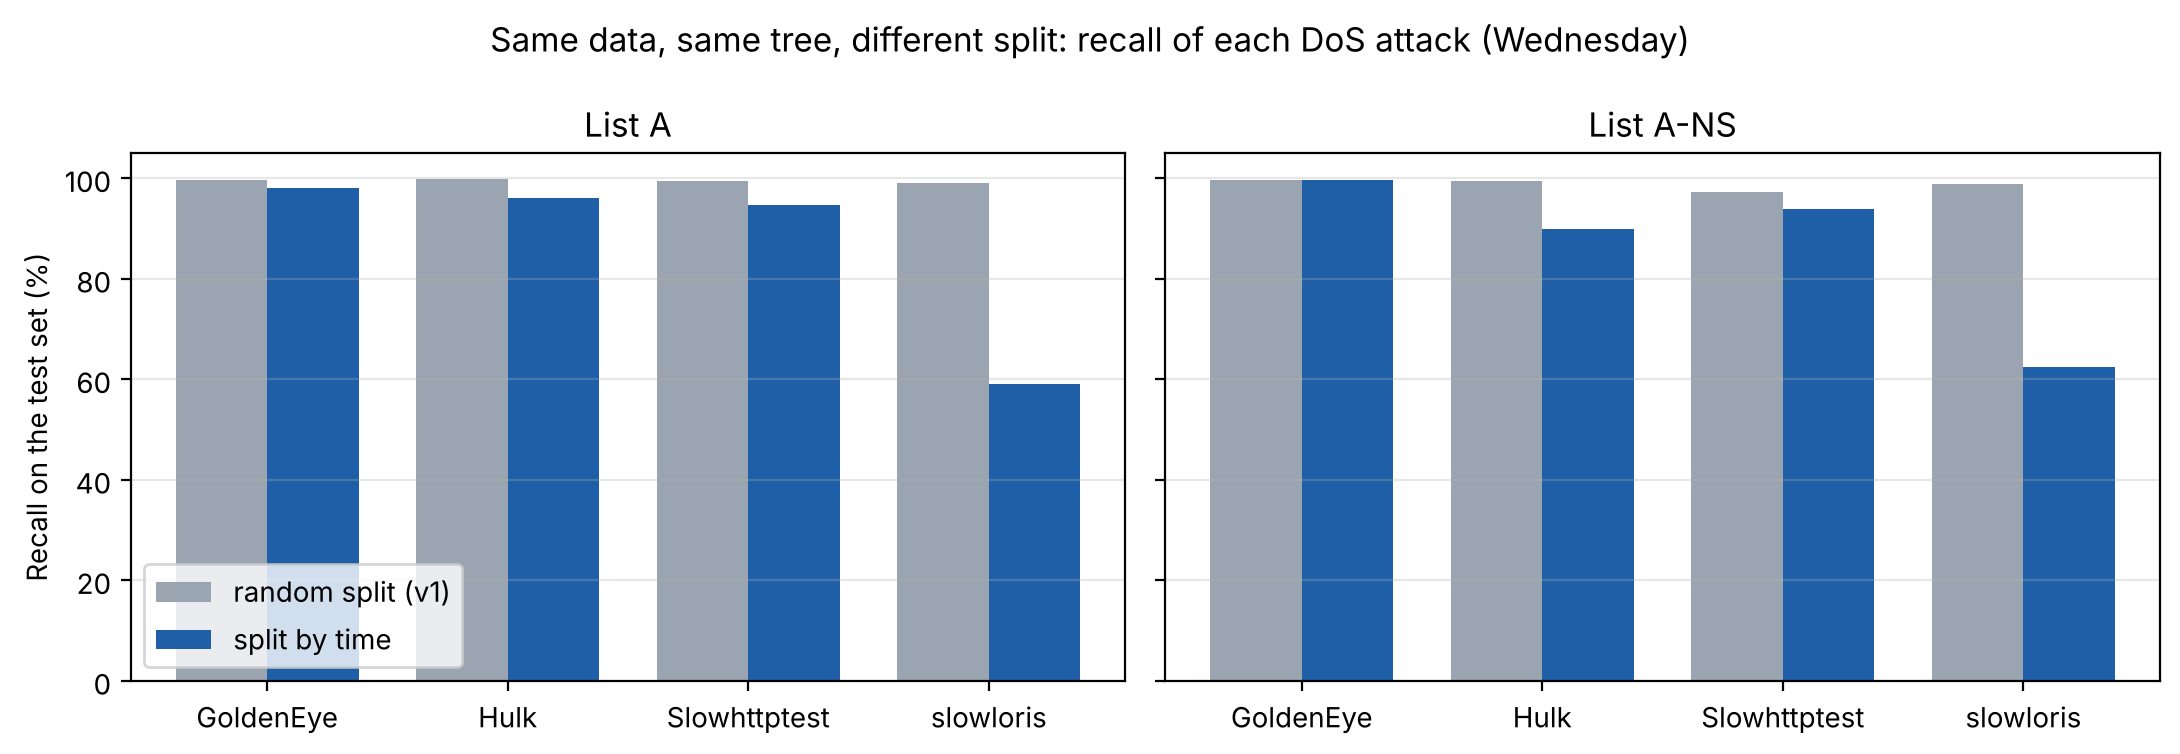

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, list_name in zip(axes, ["A", "A-NS"]):
    part = result[result["feature_list"] == list_name].set_index("split")
    x = np.arange(len(ATTACKS)); w = 0.38
    ax.bar(x - w / 2, [part.loc["random (v1)", f"recall {a}"] * 100 for a in ATTACKS], w, label="random split (v1)", color="#9aa5b1")
    ax.bar(x + w / 2, [part.loc["by time", f"recall {a}"] * 100 for a in ATTACKS], w, label="split by time", color="#1f5fa8")
    ax.set_xticks(x); ax.set_xticklabels([a.replace("DoS ", "") for a in ATTACKS])
    ax.set_title(f"List {list_name}"); ax.set_ylim(0, 105); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Recall on the test set (%)"); axes[0].legend(loc="lower left")
fig.suptitle("Same data, same tree, different split: recall of each DoS attack (Wednesday)")
fig.tight_layout()
fig.savefig(h.FIG_DIR / "fig1_random_vs_time_split.png", dpi=200)
plt.show()

## What this shows

1. **The random split is where most of the 99.9% comes from.** With nothing changed except
   the split, the score drops for every list (table above). The clearest case is DoS
   slowloris: about 99% recall with the random split and about 60% when the tree has to
   recognise the later part of the attack.
2. **It is not exact copies.** Exact duplicates were already removed in v1, and for list A
   almost no test flow has an identical training flow. The leak is *near*-copies: flows from
   the same burst that differ only slightly, which a deep tree can separate one by one.
3. **So v1's test set does not answer "will this tree catch attacks?"**, only "can this tree
   fill in the gaps in a burst it has already seen?". v2 therefore never uses a random split
   as its main test (notebooks 03 and 04).